In [1]:
!pip install -q nltk matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import math
import random
from collections import Counter

import matplotlib.pyplot as plt
import nltk
from nltk.corpus import gutenberg, stopwords
from nltk.tokenize import word_tokenize

nltk.download('gutenberg', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

print(gutenberg.fileids())

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


In [ ]:
# Training
caesar_text = gutenberg.raw('shakespeare-caesar.txt').split("\n", 1)[1]
macbeth_text = gutenberg.raw('shakespeare-macbeth.txt').split("\n", 1)[1]

# Evaluation
hamlet_text = gutenberg.raw('shakespeare-hamlet.txt').split("\n", 1)[1]

print("Caesar characters:", len(caesar_text))
print("Macbeth characters:", len(macbeth_text))
print("Hamlet characters:", len(hamlet_text))

Caesar characters: 112250
Macbeth characters: 100297
Hamlet characters: 162828


In [4]:
training_set = caesar_text + "\n" + macbeth_text
evaluation_set = hamlet_text

print("Training size: ", len(training_set))
print("Eval size: ", len(evaluation_set))

Training size:  212548
Eval size:  162828


## 1. Preprocessing

`preprocess_nltk` cleans one piece of text into a list of word tokens.

An N-gram model predicts each word from the words just before it, so sentence boundaries matter:
the first word of a sentence should not be predicted from the end of the previous one.
`preprocess_sentences` therefore splits the text into sentences first, then cleans each one.

We **keep stopwords** for language modeling: words like *the, of, to, is* carry the grammatical
structure the model has to learn (stopword removal is compared at the end of the notebook).

In [ ]:
# Stopwords without apostrophes, to match the cleaned text ("don't" -> "dont")
stop_words = set(word.replace("'", "") for word in stopwords.words('english'))

def preprocess_nltk(text, remove_stop=False):
    # 1. Lowercase
    text = text.lower()

    # 2. Remove apostrophes and hyphens inside words ("wee'l" -> "weel", "market-place" -> "market place"),
    #    otherwise step 4 would throw away the whole word
    text = text.replace("'", "").replace("-", " ")

    # 3. Tokenize into words
    tokens = word_tokenize(text)

    # 4. Remove punctuation and special characters (keep only tokens made of letters and digits)
    tokens = [token for token in tokens if token.isalnum()]

    # 5. Optional stopword removal
    if remove_stop:
        tokens = [token for token in tokens if token not in stop_words]

    return tokens

def preprocess_sentences(text, remove_stop=False):
    """Split text into sentences, then clean each sentence with preprocess_nltk."""
    sentences = []
    for sentence in nltk.sent_tokenize(text):
        tokens = preprocess_nltk(sentence, remove_stop)
        if tokens:  # skip sentences that became empty
            sentences.append(tokens)
    return sentences

train_sentences = preprocess_sentences(training_set, remove_stop=False)
eval_sentences = preprocess_sentences(evaluation_set, remove_stop=False)

print("Training:   sentences =", len(train_sentences), "| tokens =", sum(len(s) for s in train_sentences))
print("Evaluation: sentences =", len(eval_sentences), "| tokens =", sum(len(s) for s in eval_sentences))
print("Example sentence:", train_sentences[10])

Training:   sentences = 3053 | tokens = 38319
Evaluation: sentences = 2355 | tokens = 29703
Example sentence: ['what', 'dost', 'thou', 'with', 'thy', 'best', 'apparrell', 'on']


## 2. Building blocks: special tokens, vocabulary, padding, n-grams

* `<s>`: padding at the start of a sentence so the first words also have a full context.
* `</s>`: end of sentence. The model learns to predict it, which tells the generator when to stop.
* `<UNK>`: replaces every evaluation word that never appeared in training (out-of-vocabulary).

For a sentence `w1 ... wk` and order `n`, we pad it with `n-1` start tokens and one end token,
then slide a window of size `n` over it. Each window is one n-gram: the first `n-1` words are the
**context** (history), the last word is the word being **predicted**.

In [6]:
BOS = "<s>"     # start-of-sentence padding
EOS = "</s>"    # end-of-sentence marker
UNK = "<UNK>"   # any word not seen in training

def build_vocab(sentences):
    """All training words, plus </s> and <UNK>. (<s> is never predicted, so it is not included.)"""
    vocab = set()
    for sentence in sentences:
        vocab.update(sentence)
    vocab.add(EOS)
    vocab.add(UNK)
    return vocab

def replace_oov(sentences, vocab):
    """Replace words that are not in the vocabulary with <UNK>."""
    return [[word if word in vocab else UNK for word in sentence] for sentence in sentences]

def pad(sentence, n):
    return [BOS] * (n - 1) + sentence + [EOS]

def get_ngrams(sentence, n):
    """Return the list of n-grams (tuples) of a padded sentence."""
    padded = pad(sentence, n)
    return [tuple(padded[i:i + n]) for i in range(len(padded) - n + 1)]

example = ["to", "be", "or", "not"]
for n in [1, 2, 3]:
    print(f"n={n}:", get_ngrams(example, n))

n=1: [('to',), ('be',), ('or',), ('not',), ('</s>',)]
n=2: [('<s>', 'to'), ('to', 'be'), ('be', 'or'), ('or', 'not'), ('not', '</s>')]
n=3: [('<s>', '<s>', 'to'), ('<s>', 'to', 'be'), ('to', 'be', 'or'), ('be', 'or', 'not'), ('or', 'not', '</s>')]


## 3. The N-gram model with Laplace smoothing

**Training** = counting. For every n-gram in the training data we store:
* `ngram_counts[(w1, ..., wn)]`: how many times the full n-gram appears.
* `context_counts[(w1, ..., wn-1)]`: how many times the context appears (followed by any word).

**Probability** (Laplace / add-one smoothing), with `V` = vocabulary size:

$$P(w \mid \text{context}) = \frac{C(\text{context}, w) + 1}{C(\text{context}) + V}$$

For the unigram model the context is empty, `C(()) = N` (total number of training tokens), so
$P(w) = \frac{C(w) + 1}{N + V}$. The same code handles every `n`.

**Perplexity** on the evaluation set, over all `M` predicted tokens (words and `</s>`):

$$PP = \exp\left(-\frac{1}{M} \sum_{i=1}^{M} \log P(w_i \mid \text{context}_i)\right)$$

**Generation**: start with the context `<s> ... <s>`, sample the next word from
$P(w \mid \text{context})$, slide the context window, and repeat until `</s>` or `max_words`.
With `smoothing=False` we sample from the raw counts (only continuations seen in training);
with `smoothing=True` we sample from the Laplace-smoothed distribution.

In [ ]:
class NGramModel:
    def __init__(self, n):
        self.n = n
        self.ngram_counts = Counter()    
        self.context_counts = Counter() 
        self.vocab = set()

    def train(self, sentences):
        self.vocab = build_vocab(sentences)
        for sentence in sentences:
            for ngram in get_ngrams(sentence, self.n):
                self.ngram_counts[ngram] += 1
                self.context_counts[ngram[:-1]] += 1

    def prob(self, word, context):
        """Laplace-smoothed P(word | context) = (C(context, word) + 1) / (C(context) + V)."""
        V = len(self.vocab)
        return (self.ngram_counts[context + (word,)] + 1) / (self.context_counts[context] + V)

    def perplexity(self, sentences):
        sentences = replace_oov(sentences, self.vocab)
        total_log_prob = 0.0
        num_predictions = 0
        for sentence in sentences:
            for ngram in get_ngrams(sentence, self.n):
                total_log_prob += math.log(self.prob(ngram[-1], ngram[:-1]))
                num_predictions += 1
        return math.exp(-total_log_prob / num_predictions)

    def generate(self, max_words=20, smoothing=False, seed=None):
        rng = random.Random(seed)
        words = sorted(self.vocab)
        context = (BOS,) * (self.n - 1)
        output = []
        for _ in range(max_words):
            if smoothing:
                weights = [self.prob(w, context) for w in words]
            else:
                weights = [self.ngram_counts[context + (w,)] for w in words]
            word = rng.choices(words, weights=weights)[0]
            if word == EOS:
                break
            output.append(word)
            context = (context + (word,))[1:]  # slide the window: drop the oldest word, add the new one
        return " ".join(output)

### Probabilities must sum to 1

For any context (seen or unseen), $\sum_{w \in V} P(w \mid \text{context})$ must equal 1.

In [8]:
bigram = NGramModel(2)
bigram.train(train_sentences)

for context in [("the",), ("lord",), (BOS,), ("neverseenword",)]:
    total = sum(bigram.prob(w, context) for w in bigram.vocab)
    print(f"context={context!s:20} C(context)={bigram.context_counts[context]:5d}  sum of P = {total:.6f}")

context=('the',)             C(context)= 1226  sum of P = 1.000000
context=('lord',)            C(context)=   82  sum of P = 1.000000
context=('<s>',)             C(context)= 3053  sum of P = 1.000000
context=('neverseenword',)   C(context)=    0  sum of P = 1.000000


## 4. Unigram baseline

In [9]:
unigram = NGramModel(1)
unigram.train(train_sentences)

print("Vocabulary size V:", len(unigram.vocab))
print("Training tokens N (words + </s>):", unigram.context_counts[()])
print()
print("Most frequent unigrams and their smoothed probabilities:")
for (word,), count in unigram.ngram_counts.most_common(10):
    print(f"  {word:8} count={count:5d}  P={unigram.prob(word, ()):.4f}")
print()
print("Unigram perplexity on Hamlet:", round(unigram.perplexity(eval_sentences), 2))

Vocabulary size V: 5184
Training tokens N (words + </s>): 41372

Most frequent unigrams and their smoothed probabilities:
  </s>     count= 3053  P=0.0656
  the      count= 1226  P=0.0264
  and      count= 1172  P=0.0252
  i        count=  860  P=0.0185
  to       count=  829  P=0.0178
  of       count=  690  P=0.0148
  you      count=  593  P=0.0128
  that     count=  512  P=0.0110
  a        count=  508  P=0.0109
  not      count=  448  P=0.0096

Unigram perplexity on Hamlet: 811.39


## 5. Text generation

First we sample from the raw counts (`smoothing=False`): the model only picks continuations it
actually saw in training. Then we sample the bigram model from the Laplace-smoothed distribution
to see how much probability mass smoothing moves to unseen words.

In [10]:
for n in [1, 2, 3, 4, 6]:
    model = NGramModel(n)
    model.train(train_sentences)
    print(f"--- n = {n} ---")
    for seed in range(4):
        print("  ", model.generate(max_words=20, seed=seed))

--- n = 1 ---
   thorough such houre dagger liue him the euen it name vs let does strike of constant walkd you the vp
   and thou take creatures lacke ile our the againe
   with wilde
   choakd me hast not of


--- n = 2 ---
   titin


   by this secret black and like starres shall be a tempest dropping fire
   why worthy caesar
   enter lucius and referrd me
--- n = 3 ---
   titin
   by your voyce cask


   why well macd
   enter macbeth
--- n = 4 ---
   titin
   by your pardon i will my lord
   why well macd
   enter macbeth
--- n = 6 ---
   titin


   by your pardon i will my selfe into the pulpit first and shew the reason of our caesars death
   why well macd
   enter macbeth


In [11]:
print("Bigram, sampling from the Laplace-smoothed distribution:")
for seed in range(3):
    print("  ", bigram.generate(max_words=20, smoothing=True, seed=seed))

Bigram, sampling from the Laplace-smoothed distribution:
   theres shard hopes dreadfull lyable heereafter slow falles lamentings norway twaine lords encouragd shakes pent dogge twice wont stabd triumph
   carries sweetly shout doth lilly instrument preuent society bond anoynted succeeding iealousies shop abler infranchisement sacrificers deseruers vulture tried antique
   whilst walls balme birthdome suburbs scorning qualitie fasten owne padock noblest cobler husbanded hatchd safety yelld warder mile inforced dusty


## 6. Evaluation: perplexity for n = 1 ... 10

Each model is trained on Caesar + Macbeth and evaluated on Hamlet. Lower perplexity is better.

To explain the results we also measure, over the evaluation n-grams:
* **unseen n-grams**: the full n-gram never appeared in training. Without smoothing (maximum
  likelihood, $P = C(\text{context}, w) / C(\text{context})$) these get probability 0, so
  $\log P = -\infty$ and the perplexity would be infinite. For `n = 1` these are the `<UNK>` tokens.
* **unseen contexts**: even the context never appeared, so Laplace gives the uniform $1/V$.

 n | perplexity | unseen n-grams | unseen contexts
----------------------------------------------------


 1 |     811.39 |          14.0% |            0.0%
 2 |    2569.10 |          61.0% |           14.0%


 3 |    4174.09 |          87.6% |           56.1%


 4 |    4337.03 |          91.4% |           81.0%


 5 |    4345.55 |          91.6% |           84.4%


 6 |    4346.11 |          91.7% |           84.6%
 7 |    4346.30 |          91.7% |           84.6%


 8 |    4346.30 |          91.7% |           84.6%
 9 |    4346.30 |          91.7% |           84.6%


10 |    4346.30 |          91.7% |           84.6%


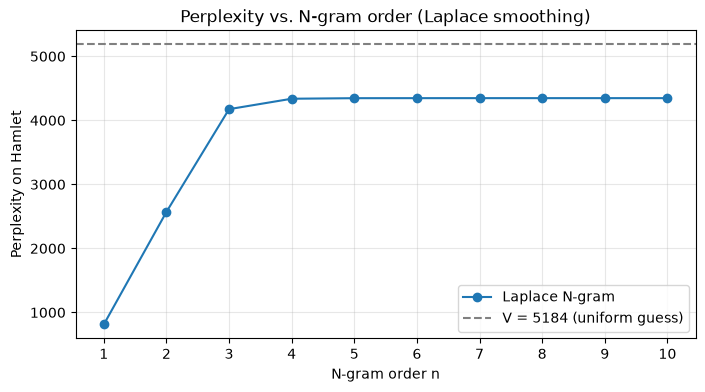

In [12]:
def unseen_stats(model, sentences):
    """Fraction of evaluation n-grams, and of their contexts, never seen in training."""
    sentences = replace_oov(sentences, model.vocab)
    total = unseen_ngrams = unseen_contexts = 0
    for sentence in sentences:
        for ngram in get_ngrams(sentence, model.n):
            total += 1
            if model.ngram_counts[ngram] == 0:
                unseen_ngrams += 1
            if model.context_counts[ngram[:-1]] == 0:
                unseen_contexts += 1
    return unseen_ngrams / total, unseen_contexts / total

orders = list(range(1, 11))
perplexities = []

print(f"{'n':>2} | {'perplexity':>10} | {'unseen n-grams':>14} | {'unseen contexts':>15}")
print("-" * 52)
for n in orders:
    model = NGramModel(n)
    model.train(train_sentences)
    pp = model.perplexity(eval_sentences)
    ngram_ratio, context_ratio = unseen_stats(model, eval_sentences)
    perplexities.append(pp)
    print(f"{n:>2} | {pp:>10.2f} | {ngram_ratio:>14.1%} | {context_ratio:>15.1%}")

V = len(unigram.vocab)
plt.figure(figsize=(8, 4))
plt.plot(orders, perplexities, marker="o", label="Laplace N-gram")
plt.axhline(V, color="gray", linestyle="--", label=f"V = {V} (uniform guess)")
plt.xticks(orders)
plt.xlabel("N-gram order n")
plt.ylabel("Perplexity on Hamlet")
plt.title("Perplexity vs. N-gram order (Laplace smoothing)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Experiment: effect of stopword removal

Same pipeline, but stopwords are removed during preprocessing. Note that the two settings are not
directly comparable: they have different vocabularies and predict different token sequences
(removing the most frequent, most predictable words changes what is being predicted).

In [13]:
train_no_stop = preprocess_sentences(training_set, remove_stop=True)
eval_no_stop = preprocess_sentences(evaluation_set, remove_stop=True)

print(f"{'n':>2} | {'with stopwords':>14} | {'stopwords removed':>17}")
print("-" * 40)
for n in orders:
    model = NGramModel(n)
    model.train(train_no_stop)
    print(f"{n:>2} | {perplexities[n - 1]:>14.2f} | {model.perplexity(eval_no_stop):>17.2f}")

 n | with stopwords | stopwords removed
----------------------------------------
 1 |         811.39 |           1886.72
 2 |        2569.10 |           3994.07
 3 |        4174.09 |           4398.55
 4 |        4337.03 |           4405.48
 5 |        4345.55 |           4405.64


 6 |        4346.11 |           4405.64
 7 |        4346.30 |           4405.64
 8 |        4346.30 |           4405.64
 9 |        4346.30 |           4405.64
10 |        4346.30 |           4405.64
